# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

**Submission: Priyanshi Goyal — A24ARIU0009**


## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [2]:
# %pip install torch torchvision matplotlib

Device: cuda


  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<01:32, 107kB/s]

  1%|          | 65.5k/9.91M [00:00<01:32, 107kB/s]

  2%|▏         | 164k/9.91M [00:00<00:47, 204kB/s] 

  3%|▎         | 262k/9.91M [00:01<00:38, 250kB/s]

... (41 outputs left out)

100%|██████████| 1.65M/1.65M [00:05<00:00, 300kB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 24.5MB/s]

Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


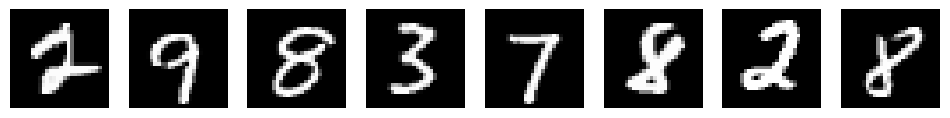

In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## Shape predictions
| Stage | Output shape |
|---|---|
| Input | `[N,1,28,28]` |
| Encoder 1 | `[N,16,14,14]` |
| Encoder 2 | `[N,32,7,7]` |
| Bottleneck | `[N,L,7,7]` |
| Decoder 1 | `[N,16,14,14]` |
| Decoder 2 | `[N,1,28,28]` |
For L=8, input = 784 values, latent = 392, ratio = 2. For L=32 the latent contains
1568 values, twice the input, so it is not dimensionally compressed. Sigmoid matches
pixels in [0,1]. Without output padding the first decoder height is
(7−1)×2−2×1+(3−1)+1 = 13.


## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [4]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(nn.Conv2d(1,16,3,2,1), nn.ReLU(),
            nn.Conv2d(16,32,3,2,1), nn.ReLU(), nn.Conv2d(32,latent_channels,1))
    def forward(self,x): return self.network(x)


In [5]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(nn.ConvTranspose2d(latent_channels,16,3,2,1,output_padding=1),
            nn.ReLU(),nn.ConvTranspose2d(16,1,3,2,1,output_padding=1),nn.Sigmoid())
    def forward(self,z): return self.network(z)


In [6]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

In [7]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [8]:
def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad(set_to_none=True)
    reconstruction, _ = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()


Untrained held-out MSE: 0.18629


Epoch 1: train MSE=0.11827, held-out MSE=0.04370


Epoch 2: train MSE=0.03428, held-out MSE=0.02552


Epoch 3: train MSE=0.01680, held-out MSE=0.00982


Epoch 4: train MSE=0.00826, held-out MSE=0.00613


Epoch 5: train MSE=0.00558, held-out MSE=0.00449


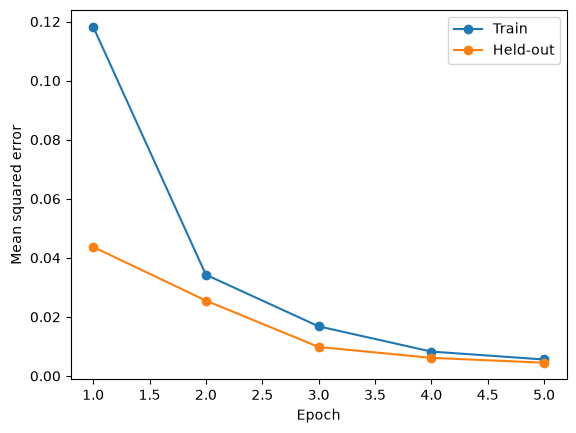

In [9]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

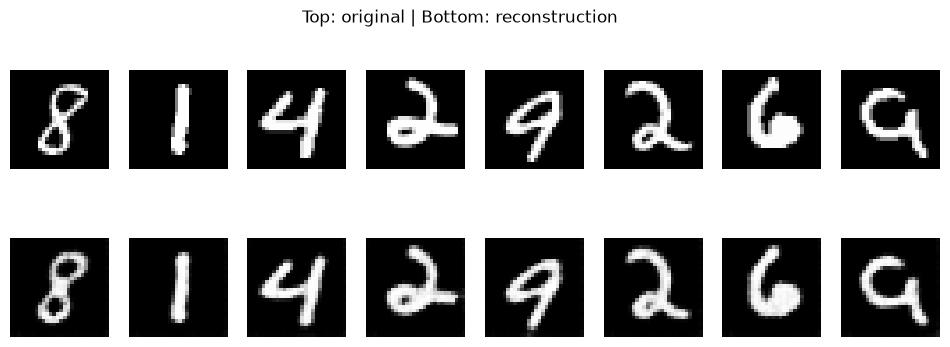

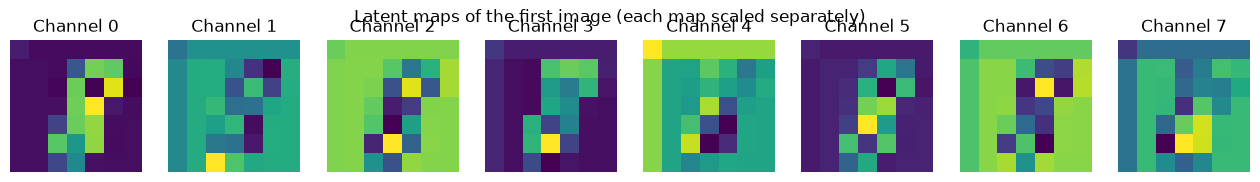

In [10]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## Bottleneck experiment: measured results
Same MNIST subsets, seed 42, Adam learning rate 0.001 and five epochs; each run starts fresh.
| Latent channels | Values | Input/latent ratio | Train MSE | Validation MSE | Visible differences |
|---|---|---|---|---|---|
| 2 | 98 | 8 | 0.012091 | 0.010687 | Blurred loops and merged strokes, especially 8 and 9 |
| 8 | 392 | 2 | 0.005623 | 0.004571 | Clearer loops and thinner, more faithful strokes |
| 32 | 1568 | 0.5 | 0.003502 | 0.002949 | Closest outlines and cleaner loop interiors |
The larger latent improved validation MSE in this run, and the plotted eight examples support
the same conclusion visually. The 32-channel model is not dimensionally compressed and has
more parameters; this comparison does not isolate compression alone. The validation subset
was repeatedly inspected and is not an untouched final benchmark.


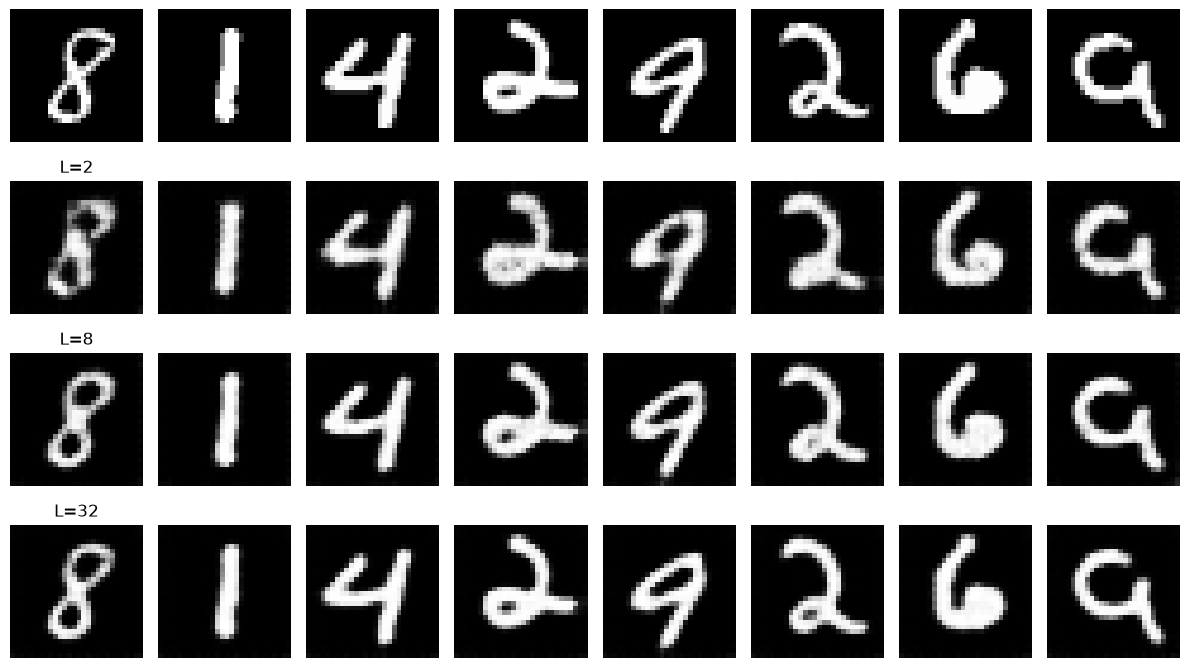

L, latent values, input/latent ratio, final train MSE, final validation MSE
[2, 98, 8.0, 0.012091471903026105, 0.01068692234903574]
[8, 392, 2.0, 0.005623185367137194, 0.004570958603173495]
[32, 1568, 0.5, 0.003502158108726144, 0.002949250413104892]


In [11]:
# Repeat the prescribed experiment with fresh models and identical seeds/data.
experiment_rows = []
fig, axes = plt.subplots(4, 8, figsize=(12, 7))
for j in range(8):
    axes[0,j].imshow(examples[j,0],cmap='gray',vmin=0,vmax=1)
    axes[0,j].axis('off')
for row, channels in enumerate([2,8,32],1):
    torch.manual_seed(42)
    experiment_model = ImageEncoderDecoder(channels).to(device)
    opt = torch.optim.Adam(experiment_model.parameters(),lr=1e-3)
    curve=[]
    for epoch in range(EPOCHS):
        experiment_model.train()
        total=0
        for batch,_ in train_loader:
            total += train_step(experiment_model,batch.to(device),opt,criterion)*len(batch)
        curve.append((total/len(train_loader.dataset),evaluate(experiment_model,test_loader)))
    experiment_rows.append([channels,channels*49,784/(channels*49),*curve[-1]])
    with torch.no_grad(): recon,_=experiment_model(examples[:8].to(device))
    for j in range(8):
        axes[row,j].imshow(recon[j,0].cpu(),cmap='gray',vmin=0,vmax=1)
        axes[row,j].axis('off')
    axes[row,0].set_title(f'L={channels}')
plt.tight_layout();plt.show()
print('L, latent values, input/latent ratio, final train MSE, final validation MSE')
for row in experiment_rows: print(row)


## Bottleneck discussion
Spatial downsampling alone does not establish compression: channels must be counted as well.
The decoder learns plausible spatial detail from training; upsampling cannot recover information
that the encoder discarded. A `[N,128]` vector has 128 values and no explicit spatial grid;
this model preserves a 7×7 grid. A skip from the first encoder map to the corresponding
14×14 decoder map can carry detailed strokes, but lets information bypass the bottleneck.
Random latent values need not resemble encoded training examples: there is no prior-matching
objective, so reconstruction training alone does not establish random-image generation.
The experiment table and plotted examples above provide the measured evidence.


## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.